## 1. Install dependencies


In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 41.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1

## 2. Import packages and create output folders

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mlflow
import mlflow.sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, RocCurveDisplay

DATA_DIR = Path('data')
ARTIFACT_DIR = Path('artifacts')
DATA_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)
SEED = 42

## 3. Import the official UCI Heart Disease dataset and save CSV


In [4]:
%pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

heart_disease = fetch_ucirepo(id=45)
features = heart_disease.data.features.copy()
original_target = heart_disease.data.targets.copy()

assert features.shape[1] == 13, f"Expected 13 features, got {features.shape[1]}"
assert 'num' in original_target.columns, "UCI target 'num' was not returned"

# Save the original data before any target transformation.
raw_df = pd.concat([features, original_target], axis=1)
raw_df.to_csv(DATA_DIR / 'heart_disease_raw.csv', index=False)

# Numeric conversion also handles any unexpected '?' placeholders as NaN.
for column in features.columns:
    features[column] = pd.to_numeric(features[column], errors='coerce')
target_num = pd.to_numeric(original_target['num'], errors='coerce')
if target_num.isna().any():
    raise ValueError('Target contains missing or invalid values')

# 0 = no disease; 1–4 = disease present.
df = features.copy()
df['target'] = (target_num > 0).astype(int)
df.to_csv(DATA_DIR / 'heart_cleaned.csv', index=False)

print('UCI dataset ID:', heart_disease.metadata.uci_id)
print('Rows and columns:', df.shape)
print('Raw data:', DATA_DIR / 'heart_disease_raw.csv')
print('Binary-target data:', DATA_DIR / 'heart_cleaned.csv')
print('Class counts:')
print(df['target'].value_counts().sort_index())
display(df.head())
display(heart_disease.variables)

UCI dataset ID: 45
Rows and columns: (303, 14)
Raw data: data/heart_disease_raw.csv
Binary-target data: data/heart_cleaned.csv
Class counts:
target
0    164
1    139
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


,name,role,type,demographic,description,units,missing_values
0,age,Feature,Integer,Age,None,years,no
1,sex,Feature,Categorical,Sex,None,None,no
2,cp,Feature,Categorical,None,None,None,no
3,trestbps,Feature,Integer,None,resting blood pressure (on admission to the ho...,mm Hg,no
4,chol,Feature,Integer,None,serum cholestoral,mg/dl,no
5,fbs,Feature,Categorical,None,fasting blood sugar > 120 mg/dl,None,no
6,restecg,Feature,Categorical,None,None,None,no
7,thalach,Feature,Integer,None,maximum heart rate achieved,None,no
8,exang,Feature,Categorical,None,exercise induced angina,None,no
9,oldpeak,Feature,Integer,None,ST depression induced by exercise relative to ...,None,no



4. Inspect missing values and descriptive statistics

In [5]:
print('Missing values by column:')
display(df.isna().sum().to_frame('missing_count'))
display(df.describe(include='all').T)
print('Duplicates:', df.duplicated().sum())

Missing values by column:


,missing_count
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


Duplicates: 0


5. EDA: class balance

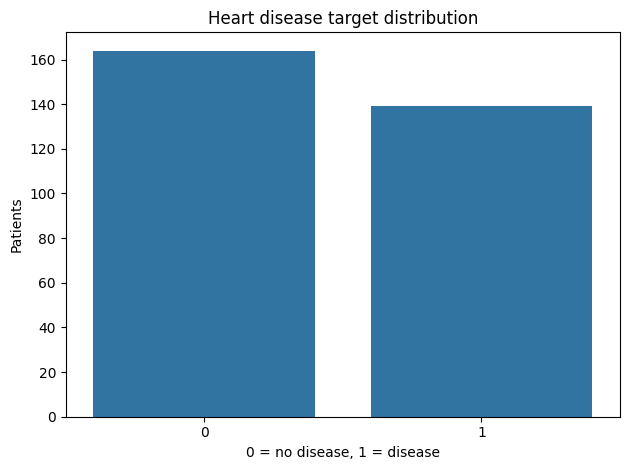

target
0    0.541
1    0.459
Name: proportion, dtype: float64


In [6]:
ax = sns.countplot(data=df, x='target')
ax.set(title='Heart disease target distribution', xlabel='0 = no disease, 1 = disease', ylabel='Patients')
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'class_balance.png', dpi=160)
plt.show()
print(df['target'].value_counts(normalize=True).round(3))

## 6. EDA: numeric histograms

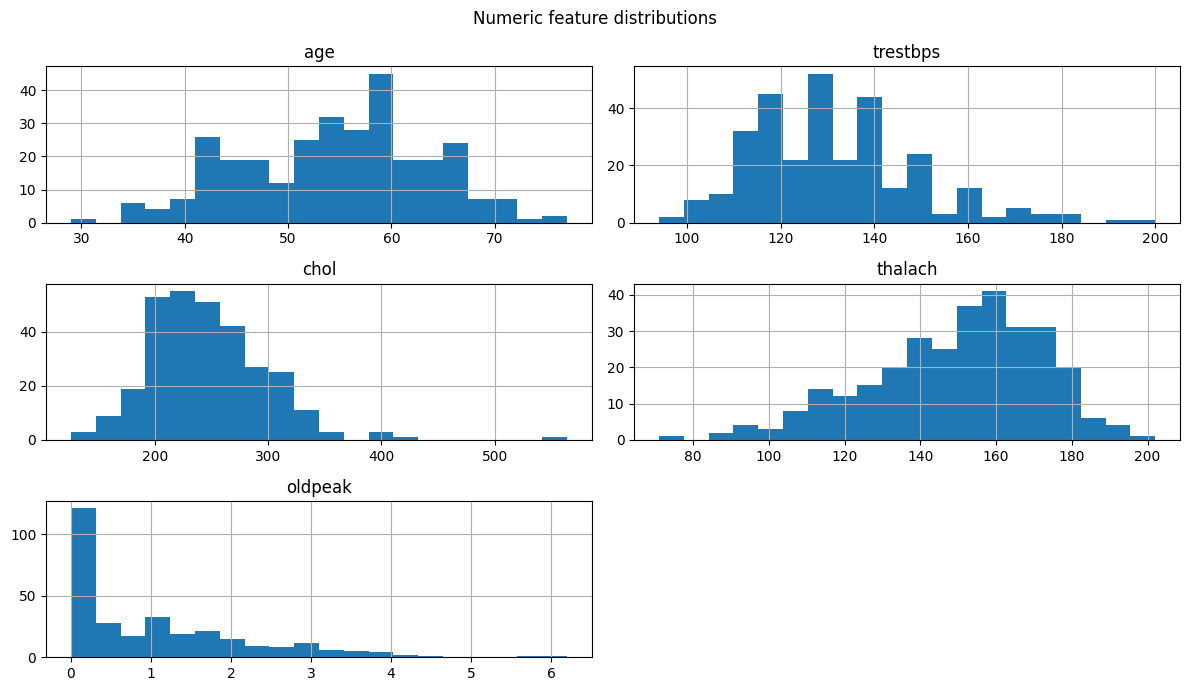

In [7]:
NUMERIC = ['age','trestbps','chol','thalach','oldpeak']
CATEGORICAL = ['sex','cp','fbs','restecg','exang','slope','ca','thal']
df[NUMERIC].hist(bins=20, figsize=(12, 7))
plt.suptitle('Numeric feature distributions')
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'histograms.png', dpi=160)
plt.show()

## 7. EDA: correlation heatmap


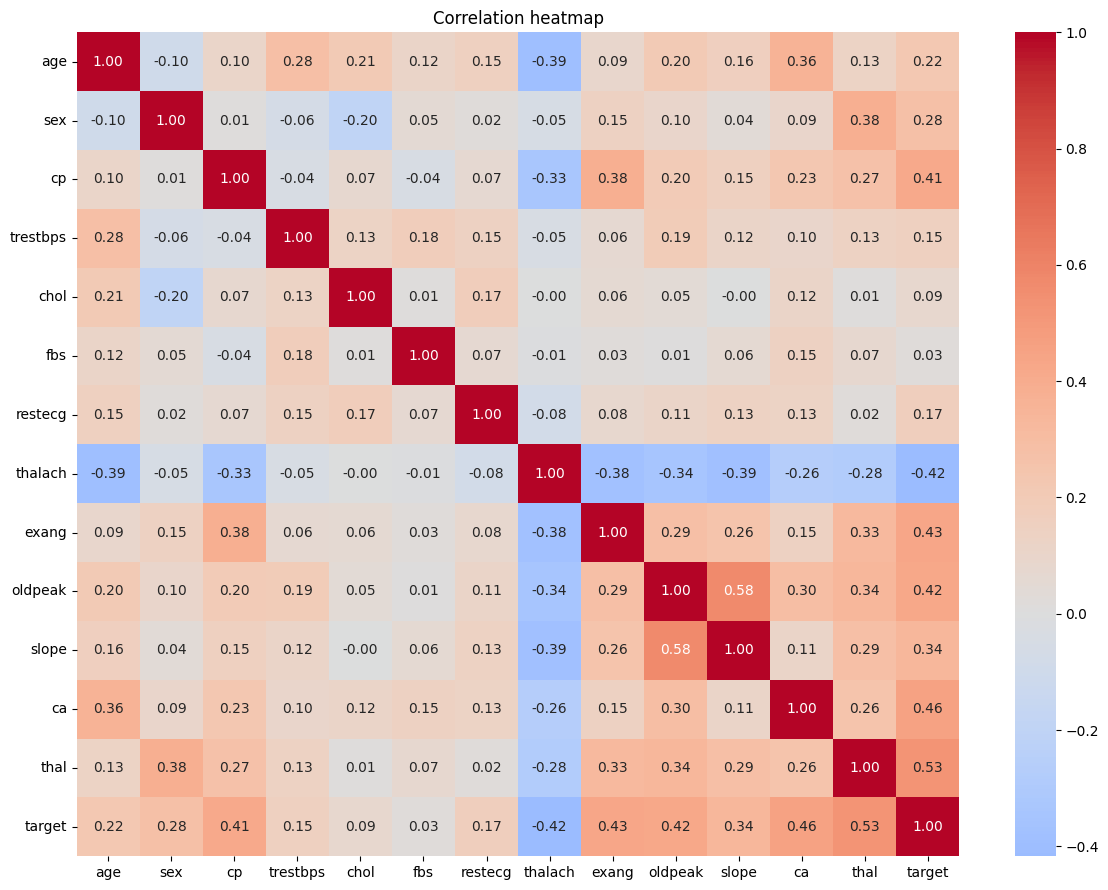

In [8]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Correlation heatmap')
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'correlation_heatmap.png', dpi=160)
plt.show()

## 8. Split the data before fitting preprocessors

In [9]:
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
print('Training:', X_train.shape, 'Testing:', X_test.shape)

Training: (242, 13) Testing: (61, 13)


## 9. Create reusable preprocessing and model pipelines

In [10]:
def build_pipeline(estimator):
    numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
    categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))])
    prep = ColumnTransformer([('numeric', numeric_pipeline, NUMERIC), ('categorical', categorical_pipeline, CATEGORICAL)])
    return Pipeline([('preprocess', prep), ('model', estimator)])

candidates = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=SEED), {'model__C':[0.1,1.0,10.0]}),
    'Random Forest': (RandomForestClassifier(random_state=SEED), {'model__n_estimators':[100,200], 'model__max_depth':[3,None]})
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

## 10. Train, tune, evaluate, and log to MLflow
Select the winner using cross-validated ROC-AUC on **training data**, not the test score. The test set is used for final reporting.

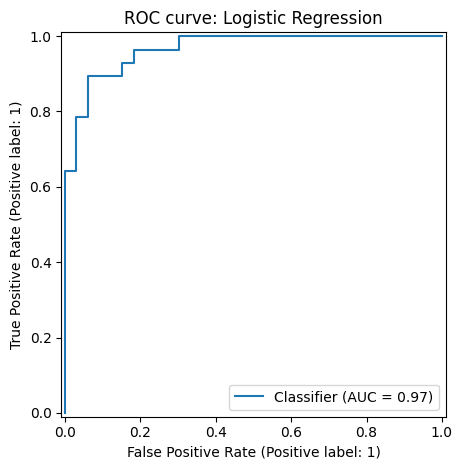

2026/10/15 18:23:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


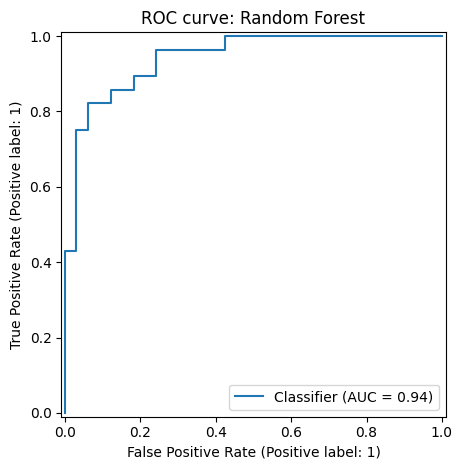

2026/10/15 18:23:58 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,model,accuracy,precision,recall,f1,test_roc_auc,cv_roc_auc,best_params
0,Logistic Regression,0.885246,0.83871,0.928571,0.881356,0.966450,0.902493,{'model__C': 1.0}
1,Random Forest,0.836066,0.80000,0.857143,0.827586,0.942641,0.897486,"{'model__max_depth': 3, 'model__n_estimators':..."


In [16]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment('heart-disease-coursework')
results = []
trained_models = {}
for name, (estimator, grid) in candidates.items():
    with mlflow.start_run(run_name=name):
        search = GridSearchCV(build_pipeline(estimator), grid, scoring='roc_auc', cv=cv, n_jobs=-1)
        search.fit(X_train, y_train)
        model = search.best_estimator_
        probabilities = model.predict_proba(X_test)[:, 1]
        predictions = model.predict(X_test)
        scores = {'accuracy':accuracy_score(y_test,predictions), 'precision':precision_score(y_test,predictions,zero_division=0), 'recall':recall_score(y_test,predictions,zero_division=0), 'f1':f1_score(y_test,predictions,zero_division=0), 'test_roc_auc':roc_auc_score(y_test,probabilities), 'cv_roc_auc':search.best_score_}
        mlflow.log_params(search.best_params_)
        mlflow.log_metrics(scores)
        RocCurveDisplay.from_predictions(y_test, probabilities)
        plt.title(f'ROC curve: {name}')
        plt.tight_layout()
        plot_path = ARTIFACT_DIR / ('roc_' + name.lower().replace(' ', '_') + '.png')
        plt.savefig(plot_path, dpi=160)
        plt.show()
        mlflow.log_artifact(str(plot_path))
        mlflow.sklearn.log_model(
    sk_model=model,
    name="model",
    serialization_format="cloudpickle"
)
        results.append({'model':name, **scores, 'best_params':str(search.best_params_)})
        trained_models[name] = model
comparison = pd.DataFrame(results).sort_values('cv_roc_auc', ascending=False)
display(comparison)
comparison.to_csv(ARTIFACT_DIR / 'model_comparison.csv', index=False)

## 11. Save selected model and metadata

In [17]:
selected_name = comparison.iloc[0]['model']
selected_model = trained_models[selected_name]
model_path = ARTIFACT_DIR / 'heart_disease_model.joblib'
joblib.dump(selected_model, model_path)
metadata = {'selected_model':selected_name, 'selection_criterion':'highest training CV ROC-AUC', 'feature_names':list(X.columns), 'metrics':comparison.to_dict(orient='records')}
(ARTIFACT_DIR / 'model_metadata.json').write_text(json.dumps(metadata, indent=2))
print('Selected:', selected_name)
print('Saved model:', model_path)
print('Saved comparison:', ARTIFACT_DIR / 'model_comparison.csv')

Selected: Logistic Regression
Saved model: artifacts/heart_disease_model.joblib
Saved comparison: artifacts/model_comparison.csv


## 12. Load saved model and predict one sample


In [18]:
loaded_model = joblib.load(ARTIFACT_DIR / 'heart_disease_model.joblib')
sample = X_test.iloc[[0]]
prediction = int(loaded_model.predict(sample)[0])
probability = float(loaded_model.predict_proba(sample)[0,1])
print('Predicted class:', prediction)
print('Predicted probability of class 1:', round(probability, 4))
print('Actual class:', int(y_test.iloc[0]))
display(sample)

Predicted class: 0
Predicted probability of class 1: 0.2093
Actual class: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
219,59,1,4,138,271,0,2,182,0,0.0,1,0.0,3.0


## 13. Final evaluation and screenshots

              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



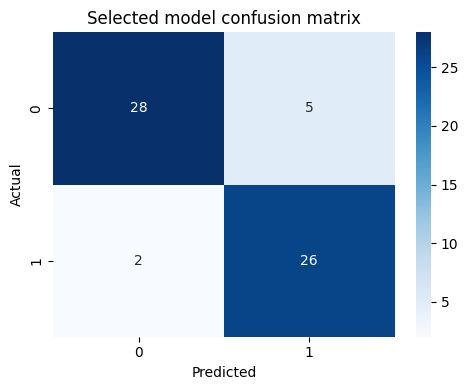

Screenshots: data preview, EDA figures, model comparison, MLflow UI, saved model and prediction.


In [19]:
final_predictions = loaded_model.predict(X_test)
print(classification_report(y_test, final_predictions, zero_division=0))
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, final_predictions), annot=True, fmt='d', cmap='Blues', xticklabels=[0,1], yticklabels=[0,1])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Selected model confusion matrix')
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'confusion_matrix.png', dpi=160)
plt.show()
print('Screenshots: data preview, EDA figures, model comparison, MLflow UI, saved model and prediction.')

In [20]:
from google.colab import files
from pathlib import Path
import shutil

# Verify the saved model exists
model_path = Path("artifacts/heart_disease_model.joblib")
assert model_path.exists(), "Model file not found. Check Step 13."

# Package generated artifacts
shutil.make_archive(
    "heart_disease_artifacts",
    "zip",
    "artifacts"
)

files.download("heart_disease_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>